# Mushroom Classification (Edible vs Poisonous)
This project uses the UCI Mushroom dataset to predict whether a mushroom is edible or poisonous, and compares three classification models.

**Models:** Logistic Regression, Decision Tree, Random Forest
**Key metric:** Recall for the poisonous class, because missing a poisonous mushroom is the costly mistake.

## 1. Import libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")

## 2. Load the data
The UCI Mushroom dataset is loaded through OpenML (internet connection required).

In [2]:
data = fetch_openml("mushroom", version=1, as_frame=True, parser="auto")
X = data.data.copy()      # features (categorical columns)
y = data.target.copy()    # 'e' = edible, 'p' = poisonous

print("Rows, Columns:", X.shape)
X.head()

Rows, Columns: (8124, 22)


,cap-shape,cap-surface,cap-color,bruises%3F,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,x,s,n,t,p,f,c,n,k,e,...,s,w,w,p,w,o,p,k,s,u
1,x,s,y,t,a,f,c,b,k,e,...,s,w,w,p,w,o,p,n,n,g
2,b,s,w,t,l,f,c,b,n,e,...,s,w,w,p,w,o,p,n,n,m
3,x,y,w,t,p,f,c,n,n,e,...,s,w,w,p,w,o,p,k,s,u
4,x,s,g,f,n,f,w,b,k,t,...,s,w,w,p,w,o,e,n,a,g


## 3. Exploratory Data Analysis (EDA)

class
e    4208
p    3916
Name: count, dtype: int64


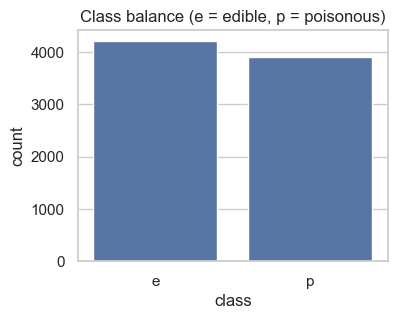

In [7]:
# Check the class balance
print(y.value_counts())

plt.figure(figsize=(4, 3))
sns.countplot(x=y)
plt.title("Class balance (e = edible, p = poisonous)")
plt.show()

In [6]:
# Check for missing values
missing = X.isna().sum()
print(missing[missing > 0])

Series([], dtype: int64)


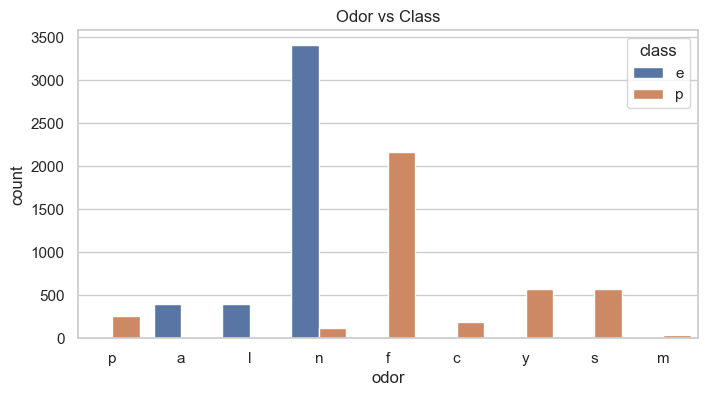

In [5]:
# How does 'odor' relate to the class?
plt.figure(figsize=(8, 4))
sns.countplot(x=X["odor"], hue=y)
plt.title("Odor vs Class")
plt.show()

## 4. Preprocessing

In [3]:
# Treat missing values as their own category
X = X.astype(object).fillna("missing")

# Convert categorical features to numbers (One-Hot Encoding)
X_encoded = pd.get_dummies(X)

# Target: 1 = poisonous, 0 = edible
y_encoded = (y == "p").astype(int)

print("Encoded shape:", X_encoded.shape)

Encoded shape: (8124, 117)


In [4]:
# Train/test split (80/20); stratify keeps the class ratio the same in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (6499, 117)  Test: (1625, 117)


## 5. Train and compare models

In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

results = []
trained = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    trained[name] = model
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),   # poisonous class (1)
    })

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df

,Accuracy,Precision,Recall
Model,,,
Logistic Regression,0.9994,1.0,0.9987
Decision Tree,1.0000,1.0,1.0000
Random Forest,1.0000,1.0,1.0000


## 6. Confusion matrix

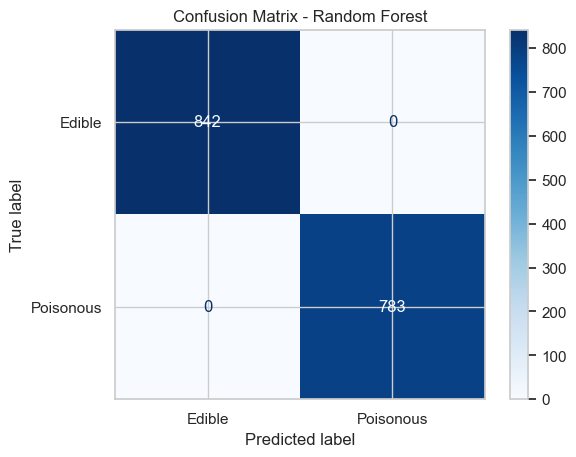

In [9]:
best_name = "Random Forest"   # change this to match your results
pred = trained[best_name].predict(X_test)

cm = confusion_matrix(y_test, pred)
disp = ConfusionMatrixDisplay(cm, display_labels=["Edible", "Poisonous"])
disp.plot(cmap="Blues")
plt.title(f"Confusion Matrix - {best_name}")

os.makedirs("images", exist_ok=True)
plt.savefig("images/confusion_matrix.png", dpi=150, bbox_inches="tight")  # use this image in the README
plt.show()

## 7. Most important features

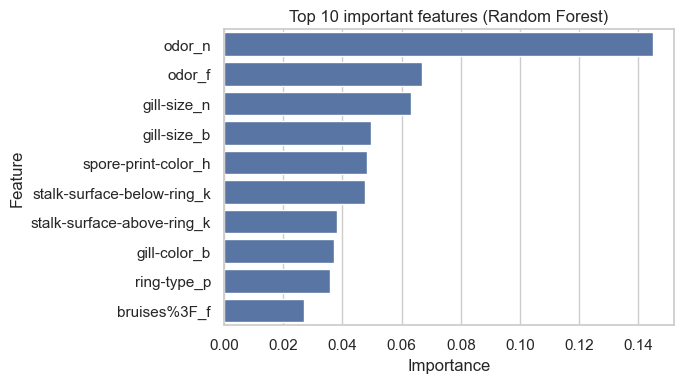

In [10]:
rf = trained["Random Forest"]
importances = pd.Series(rf.feature_importances_, index=X_encoded.columns)
top10 = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(7, 4))
sns.barplot(x=top10.values, y=top10.index)
plt.title("Top 10 important features (Random Forest)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("images/feature_importance.png", dpi=150)
plt.show()


## 8. Conclusions
- **Best performing model:** Decision Tree and Random Forest both achieved 100% accuracy, precision and recall on the test set. Logistic Regression was very close, with 99.94% accuracy and 99.87% recall. I prefer Random Forest because it combines many trees and is more stable than a single Decision Tree.
- **Most important feature:** The most important features were `odor_n` (no odor) and `odor_f` (foul odor). Mushrooms with no odor were mostly edible, while foul odors were poisonous. This matches the odor vs class plot in the EDA.
- **Why recall for the poisonous class matters:** A false negative means a poisonous mushroom is predicted as edible, which could cause serious harm. A false positive only means a safe mushroom is wrongly rejected. So recall for the poisonous class matters more than overall accuracy, and my goal was to keep missed poisonous mushrooms as close to zero as possible.
- **Why accuracy is so high on this dataset:** The features, especially odor, separate the two classes very clearly, so even simple models can classify them almost perfectly. The dataset is also fairly balanced and very clean. High accuracy here doesn't mean the model would be as good on messy real-world data, so I treat this as a learning project, not a production system.